# Building Your First Artificial Neural Network (ANN) for Regression
### A Beginner-Friendly Training Session

Welcome! In this hands-on notebook, you will learn how to build, train, and evaluate an **Artificial Neural Network (ANN)** to solve a **regression problem** (predicting a continuous number).

####  What Makes This Dataset Special?
Real-world data rarely follows a simple straight line. Our dataset (`complex_energy_regression_1000.csv`) has **1,000 rows** of building energy usage with **hidden non-linear patterns**:
- **U-shaped curve**: Both very cold and very hot temperatures increase energy use.
- **Interaction effect**: High humidity spikes energy *only* when it is already hot.
- **Time-of-day waves**: Morning and evening peaks follow a repeating cycle.
- **Saturation & diminishing returns**: Solar panels and occupancy don't scale in a straight line.

Because a simple straight-line model (Linear Regression) cannot easily see these curves, we will compare it against an **ANN** so you can watch the neural network discover the patterns automatically!

## Step 1: Import the Tools We Need
Think of libraries as toolboxes. We use:
- `pandas` & `numpy`: To load and work with tables of numbers.
- `matplotlib` & `seaborn`: To draw charts so we can *see* the patterns.
- `scikit-learn`: To split our data, scale numbers, and test a simple baseline model.
- `tensorflow` (Keras): To build and train our Artificial Neural Network.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds so everyone in the class gets similar results
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Step 2: Load and Explore the Dataset
Let's load `complex_energy_regression_1000.csv` and check its first few rows, shape, and summary statistics.

In [2]:
# Load the 1,000-row dataset
df = pd.read_csv("complex_energy_regression_1000.csv")

print("Dataset Shape (Rows, Columns):", df.shape)
df.head()

Dataset Shape (Rows, Columns): (1000, 8)


,Temperature_C,Humidity_Pct,Hour_of_Day,Occupancy_Count,Solar_Irradiance_Wm2,Equipment_Load_Index,Is_Weekend,Energy_Consumption_kWh
0,34.77,24.65,7,5,340.95,6.48,1,55.78
1,24.04,54.37,20,0,16.30,4.91,0,28.86
2,37.48,29.68,0,16,16.57,3.90,0,57.68
3,32.32,31.42,10,17,663.70,6.33,1,50.06
4,13.01,67.42,19,20,22.63,1.23,0,49.23


In [3]:
# Check for any missing values and view column types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature_C           1000 non-null   float64
 1   Humidity_Pct            1000 non-null   float64
 2   Hour_of_Day             1000 non-null   int64  
 3   Occupancy_Count         1000 non-null   int64  
 4   Solar_Irradiance_Wm2    1000 non-null   float64
 5   Equipment_Load_Index    1000 non-null   float64
 6   Is_Weekend              1000 non-null   int64  
 7   Energy_Consumption_kWh  1000 non-null   float64
dtypes: float64(5), int64(3)
memory usage: 62.6 KB


In [4]:
# Summary statistics (min, max, average) for each column
df.describe().round(2)

,Temperature_C,Humidity_Pct,Hour_of_Day,Occupancy_Count,Solar_Irradiance_Wm2,Equipment_Load_Index,Is_Weekend,Energy_Consumption_kWh
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,25.91,58.14,11.24,12.50,295.57,5.42,0.28,52.17
std,9.33,21.70,7.02,7.35,357.74,2.61,0.45,19.36
min,10.04,20.04,0.00,0.00,0.00,1.00,0.00,13.43
25%,17.69,38.71,6.00,6.00,10.98,3.16,0.00,38.84
50%,25.84,57.24,11.00,13.00,24.46,5.48,0.00,48.60
75%,34.28,77.23,18.00,19.00,631.04,7.72,1.00,61.90
max,41.97,94.96,23.00,25.00,1000.00,9.99,1.00,126.24


### Column Guide
| Column | Meaning |
|---|---|
| `Temperature_C` | Outdoor temperature in Celsius |
| `Humidity_Pct` | Relative humidity (%) |
| `Hour_of_Day` | Hour from `0` (midnight) to `23` (11 PM) |
| `Occupancy_Count` | Number of people in the building |
| `Solar_Irradiance_Wm2` | Sunlight strength hitting rooftop solar panels |
| `Equipment_Load_Index` | Appliance & machinery usage level (`1` to `10`) |
| `Is_Weekend` | `0` = Weekday, `1` = Weekend |
| **`Energy_Consumption_kWh`** | **Target to predict** (total energy used in kWh) |

## Step 4: Prepare the Data (Split & Scale)
Two golden rules before feeding data into a Neural Network:
1. **Train / Test Split (80% / 20%)**: We hide 20% of the data (200 rows) as a "final exam" so we know if the ANN truly learned the patterns instead of memorizing answers.
2. **Feature Scaling (`StandardScaler`)**: Neural networks learn much faster and more accurately when all input numbers are on a similar scale (around `-2` to `+2`), rather than mixing `Hour_of_Day` (`0–23`) with `Solar_Irradiance_Wm2` (`0–1000`).

>  **Important**: Always `fit` the scaler **only** on the training data, then `transform` both train and test data. This prevents "data leakage" from the test set!

In [6]:
# Separate inputs (X) and target (y)
X = df.drop(columns=["Energy_Consumption_kWh"])
y = df["Energy_Consumption_kWh"]

# Split into 800 training rows and 200 testing rows
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale the input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

Training samples: 800
Testing samples: 200


## Step 5: Baseline Check — Why Linear Regression Struggles
Let's first test a simple **Linear Regression** model. Since it can only draw a flat straight plane through the data, let's see how well (or poorly!) it scores.

In [7]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_mae = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression -> R2 Score: {lr_r2:.3f} | RMSE: {lr_rmse:.2f} kWh | MAE: {lr_mae:.2f} kWh")

Linear Regression -> R2 Score: 0.558 | RMSE: 13.26 kWh | MAE: 11.06 kWh


Notice that Linear Regression misses a huge chunk of the patterns! Now let's see what an **Artificial Neural Network** can do.

## Step 6: Build Your First ANN
An ANN is built out of layers of "neurons":
- **Input Layer**: Receives our 7 scaled features.
- **Hidden Layer 1 (`64` neurons, `ReLU` activation)**: Learns basic curved building blocks. (`ReLU` simply turns negative numbers into `0`, which lets the network bend and curve!)
- **Hidden Layer 2 (`32` neurons, `ReLU` activation)**: Combines those curves into complex patterns (like temperature × humidity interactions).
- **Output Layer (`1` neuron, no activation)**: Outputs our single predicted number (`Energy_Consumption_kWh`).

In [8]:
model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dense(1)  # 1 neuron for regression output
])

# Print the architecture and total trainable parameters (weights & biases)
model.summary()

C:\Users\dell\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Compile & Train the ANN
- **Optimizer (`adam`)**: The smart engine that adjusts the network's weights step by step.
- **Loss (`mse` - Mean Squared Error)**: Measures how far off the predictions are from the true energy values.
- **Epochs (`120`)**: How many times the network practices on the entire training set.
- **Validation Split (`0.2`)**: Sets aside 20% of the training data during practice so we can monitor progress on unseen data at every epoch.
- **EarlyStopping**: Automatically stops training if the validation loss stops improving, preventing overfitting!

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=120,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 2834.3433 - mae: 49.5957 - val_loss: 2358.3552 - val_mae: 45.0034
Epoch 2/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1579.5425 - mae: 34.7341 - val_loss: 573.3648 - val_mae: 19.3484
Epoch 3/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 293.3300 - mae: 13.1576 - val_loss: 205.7939 - val_mae: 11.5217
Epoch 4/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 159.2029 - mae: 10.0511 - val_loss: 133.9118 - val_mae: 9.2510
Epoch 5/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 122.2680 - mae: 9.0333 - val_loss: 111.5954 - val_mae: 8.5764
Epoch 6/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 97.2184 - mae: 7.9972 - val_loss: 89.6942 - val_mae: 7.6800
Epoch 7/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 76.3814 - mae: 7.0931 - val_loss: 74.0858 - val_mae: 7.0499
Epoch 8/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 60.0156 - mae: 6.2741 - val_loss: 62.3648 - val_mae: 6.5083
Epoch 9/120
20/20 ━━━━━━━━━

## Step 8: Plot the Learning Curve
Always check your learning curve!
- If both **Training Loss** and **Validation Loss** go down smoothly and stay close together, your ANN learned real patterns.
- If Training Loss keeps dropping while Validation Loss starts rising, the model is **overfitting** (memorizing noise).

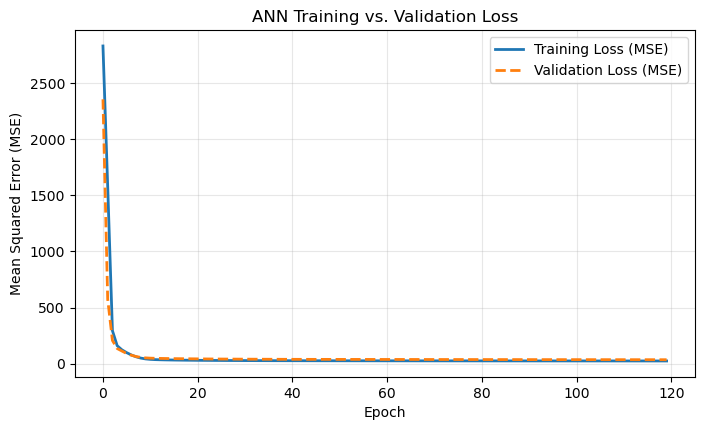

In [10]:
plt.figure(figsize=(8, 4.5))
plt.plot(history.history["loss"], label="Training Loss (MSE)", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss (MSE)", linewidth=2, linestyle="--")
plt.title("ANN Training vs. Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 9: Evaluate on the Test Set & Compare Models
Now let's test our trained ANN on the 200 hidden test rows and compare it side-by-side with Linear Regression!

In [11]:
y_pred_ann = model.predict(X_test_scaled).flatten()

ann_r2 = r2_score(y_test, y_pred_ann)
ann_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ann))
ann_mae = mean_absolute_error(y_test, y_pred_ann)

print("=== Model Comparison on Test Set ===")
print(f"Linear Regression -> R2: {lr_r2:.3f} | RMSE: {lr_rmse:.2f} kWh | MAE: {lr_mae:.2f} kWh")
print(f"ANN Model         -> R2: {ann_r2:.3f} | RMSE: {ann_rmse:.2f} kWh | MAE: {ann_mae:.2f} kWh")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
=== Model Comparison on Test Set ===
Linear Regression -> R2: 0.558 | RMSE: 13.26 kWh | MAE: 11.06 kWh
ANN Model         -> R2: 0.911 | RMSE: 5.94 kWh | MAE: 4.68 kWh


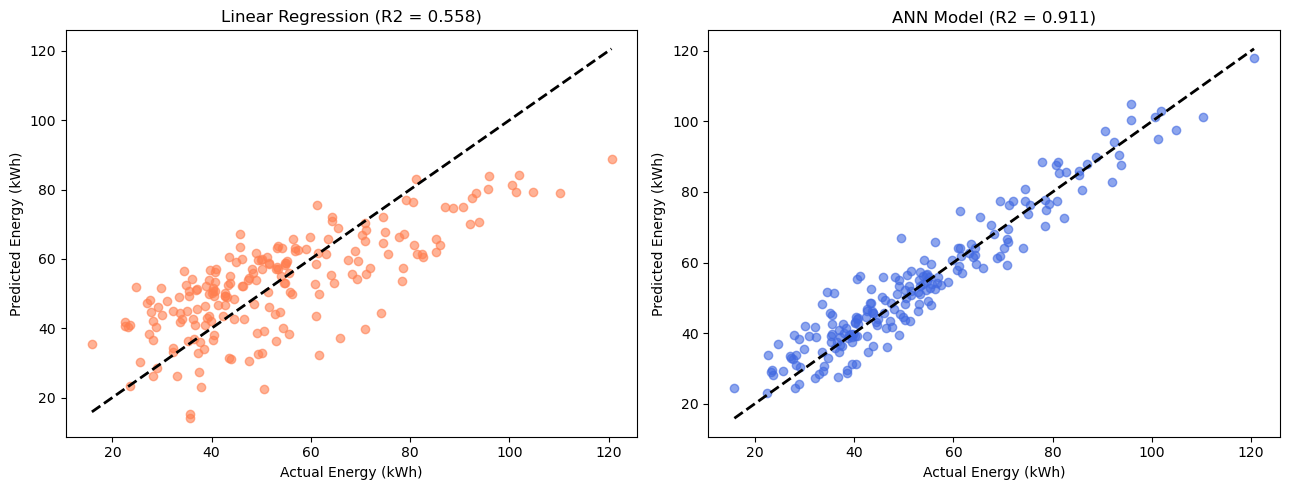

In [12]:
# Visual comparison: Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Linear Regression plot
axes[0].scatter(y_test, y_pred_lr, alpha=0.6, color="coral")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=2)
axes[0].set_title(f"Linear Regression (R2 = {lr_r2:.3f})")
axes[0].set_xlabel("Actual Energy (kWh)")
axes[0].set_ylabel("Predicted Energy (kWh)")

# ANN plot
axes[1].scatter(y_test, y_pred_ann, alpha=0.6, color="royalblue")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=2)
axes[1].set_title(f"ANN Model (R2 = {ann_r2:.3f})")
axes[1].set_xlabel("Actual Energy (kWh)")
axes[1].set_ylabel("Predicted Energy (kWh)")

plt.tight_layout()
plt.show()

## Step 10: Make a Custom Prediction!
Let's pretend it's a hot, humid weekday afternoon (`36°C`, `85%` humidity, `15:00`, `12` people, `700 W/m²` solar, `6.5` equipment load). Remember: we must scale the new input using the **exact same `scaler`** before asking the ANN for a prediction!

In [13]:
sample_input = pd.DataFrame([{
    "Temperature_C": 36.0,
    "Humidity_Pct": 85.0,
    "Hour_of_Day": 15,
    "Occupancy_Count": 12,
    "Solar_Irradiance_Wm2": 700.0,
    "Equipment_Load_Index": 6.5,
    "Is_Weekend": 0
}])

sample_scaled = scaler.transform(sample_input)
predicted_kwh = model.predict(sample_scaled)[0][0]
print(f"Predicted Energy Consumption: {predicted_kwh:.2f} kWh")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Predicted Energy Consumption: 76.88 kWh


---
##  Student Practice Challenges
Try experimenting with the notebook to see how ANNs behave:
1. **Change Network Size**: What happens if you use only 1 hidden layer with `8` neurons instead of `64 -> 32`? Does the $R^2$ score drop?
2. **Try Another Activation**: Replace `activation="relu"` with `activation="tanh"` and re-run. How does the loss curve change?
3. **Skip Feature Scaling**: What happens if you train the ANN on `X_train` (unscaled) instead of `X_train_scaled`? (Hint: watch the loss!)

In [14]:
model.save("energy_model.keras")